# 32. Sensitivity of the B20 Chaparral M25

B20's Chaparral M25 (HDF) and its infraBSU (HD1) share Centaur Sensor B: same input range (1 Vpp all
year; every 2026 B20 response file gives 16 × 10⁶ counts/V for both), same digitizer and filters. In a band
where both sensors are flat (0.3–12 Hz), the ratio of their raw counts is therefore the ratio of their
sensitivities:

$$S_{M25} = \frac{\text{counts}_{HDF}}{\text{counts}_{HD1}}\; S_{infraBSU}, \qquad S_{infraBSU} = 46\ \mu\mathrm{V\,Pa^{-1}}.$$

The ratio is estimated only where HDF is not clipped (raw counts below 80% of full scale) and the two are
coherent (median coherence ≥ 0.8 at 0.5–5 Hz). It uses the geometric mean of the H1 and H2 transfer-function
estimators, which bracket the true ratio when either record has incoherent noise. Signals:

* the decaying rocket noise in the 15 minutes after each of the 2026 Florida launches (HDF clips during
  every launch itself; list from the public Launch Library 2 database, `data/`);
* the explosion: the pre-event 4 minutes and the coda from 60 s on;
* the airwave of the Atlas V launch on the evening of the explosion day.

Artemis II cannot be used: B20's Centaur has no data for days 071–093, which include the launch (day 091).

The answer carries the infraBSU's own calibration uncertainty, which the Artemis II papers will set.

Output (`cfg.OUT_DIR / "32_chaparral_sensitivity"`): `chaparral_windows.csv`, `chaparral_epochs.csv`,
`chaparral_sensitivity.png`, `b20_response_gains.csv`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from obspy import UTCDateTime
from scipy.signal import csd, welch

import ksclib
import newglenn_config as cfg

warnings.filterwarnings('ignore')
OUT = cfg.output_dir('32_chaparral_sensitivity')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
SDS = cfg.MASTER_SDS
S_BSU = 46e-6                          # V/Pa, infraBSU (0.5 inch)
FULL = 2 ** 23
CLIP_FRAC, COH_MIN = 0.8, 0.8
BAND = (0.3, 12.0)
VISITS = [UTCDateTime('2026-04-04T23:36:08'), UTCDateTime('2026-06-14T15:33:33')]   # B20 response files: 500 -> 100 -> 500 sps
launches = pd.read_csv(cfg.PAPER_DIR / 'data' / 'launches_florida_2026_launchlibrary.csv')
print(len(launches), 'launches')

56 launches


## Check: the two sensors share one gain

Every B20 Centaur response file written in 2026 is read, and the digitizer gain (counts per volt, with the
input stage) of the Chaparral channel (HDF) is compared with that of the infraBSU channel (HD1). The Centaur response files name them DDF and DD1. If they are
equal in every file, the ratio of raw counts is the ratio of sensor sensitivities whatever the configuration.

In [2]:
from obspy import read_inventory
files = sorted(set(cfg.EVENT.project_root.glob('2026*_service/00_download/Centaur*/responses/1R.B20_*Z.xml')),
               key=lambda p: p.name)
rows = []
for p in files:
    inv = read_inventory(str(p))
    ch = {c.code: c for c in inv[0][0] if c.code in ('DDF', 'DD1')}
    g = {k: c.response.instrument_sensitivity.value for k, c in ch.items()}
    rows.append(dict(file=p.name, samples_per_s=ch['DD1'].sample_rate, DDF_counts_per_V=g['DDF'], DD1_counts_per_V=g['DD1'],
                     input_stage_gain=ch['DD1'].response.response_stages[1].stage_gain, equal=bool(np.isclose(g['DDF'], g['DD1']))))
gains = pd.DataFrame(rows).drop_duplicates('file')
gains.to_csv(OUT / 'b20_response_gains.csv', index=False)
display(gains)
assert gains.equal.all(), 'DDF and DD1 gains differ in some response file'
print(f'{len(gains)} response files, {gains.file.str[7:15].min()} to {gains.file.str[7:15].max()}: DDF and DD1 gains equal in all')

,file,samples_per_s,DDF_counts_per_V,DD1_counts_per_V,input_stage_gain,equal
0,1R.B20_20260111T150947Z.xml,500.0,16000000.0,16000000.0,40.0,True
1,1R.B20_20260404T231759Z.xml,500.0,16000000.0,16000000.0,40.0,True
2,1R.B20_20260404T233608Z.xml,100.0,16000000.0,16000000.0,40.0,True
3,1R.B20_20260509T214544Z.xml,100.0,16000000.0,16000000.0,40.0,True
4,1R.B20_20260605T185650Z.xml,100.0,16000000.0,16000000.0,40.0,True
5,1R.B20_20260614T150456Z.xml,100.0,16000000.0,16000000.0,40.0,True
6,1R.B20_20260614T151133Z.xml,100.0,16000000.0,16000000.0,40.0,True
7,1R.B20_20260614T153333Z.xml,500.0,16000000.0,16000000.0,40.0,True


8 response files, 20260111 to 20260614: DDF and DD1 gains equal in all


## Ratio in sliding windows

In [3]:
def get(suffix, t0, t1):
    # either band letter: the archive's D, or SEED C (>= 250 sps) / H (100 sps, 4 Apr-14 Jun 2026)
    s = ksclib.read_sds_files(SDS, '1R', 'B20', '00', '[CDH]' + suffix, t0, t1)
    for tr in s:
        tr.data = tr.data.astype(np.float64)
    s.merge(fill_value=0)
    return s[0] if len(s) == 1 else None

def ratio_windows(t0, t1, win=30.0, step=30.0, source=''):
    a, b = get('D1', t0 - 30, t1 + 30), get('DF', t0 - 30, t1 + 30)
    if a is None or b is None:
        return []
    fs = a.stats.sampling_rate
    braw = b.copy()
    for tr in (a, b):
        tr.detrend('demean')
        tr.filter('bandpass', freqmin=BAND[0], freqmax=BAND[1], corners=4, zerophase=True)
    rows = []
    for w0 in np.arange(0, t1 - t0 - win + 1e-6, step):
        w = (t0 + w0, t0 + w0 + win)
        r = braw.slice(*w).data
        if len(r) < win * fs * 0.9 or np.abs(r).max() > CLIP_FRAC * FULL:
            continue
        x, y = a.slice(*w).data, b.slice(*w).data
        n = min(len(x), len(y)); x, y = x[:n], y[:n]
        nps = int(4 * fs)
        f, pxy = csd(x, y, fs, nperseg=nps)
        _, pxx = welch(x, fs, nperseg=nps)
        _, pyy = welch(y, fs, nperseg=nps)
        co = np.abs(pxy) ** 2 / (pxx * pyy)
        m = (f >= 0.5) & (f <= 5)
        if np.median(co[m]) < COH_MIN:
            continue
        h1, h2 = np.median(np.abs(pxy[m]) / pxx[m]), np.median(pyy[m] / np.abs(pxy[m]))
        rows.append(dict(source=source, t=str(w[0]), fs=fs, dd1_rms_Pa=x.std() / (S_BSU * 16e6), coherence=np.median(co[m]),
                         H1=h1, H2=h2, H=np.sqrt(h1 * h2)))
    return rows

rows = []
for _, r in launches.iterrows():
    t = UTCDateTime(r.net)
    rows += ratio_windows(t, t + 900, source=f"launch: {r['name']}")
O = cfg.ORIGIN
rows += ratio_windows(O - 270, O - 10, source='explosion: pre-event')
rows += ratio_windows(O + 60, O + 300, source='explosion: coda')
win = pd.DataFrame(rows)
win['t'] = pd.to_datetime(win.t)
win['S_V_per_Pa'] = win.H * S_BSU
win['epoch'] = pd.cut(win.t, [pd.Timestamp('2026-01-01', tz='UTC'), pd.Timestamp(VISITS[0].datetime, tz='UTC'),
                              pd.Timestamp(VISITS[1].datetime, tz='UTC'), pd.Timestamp('2027-01-01', tz='UTC')],
                      labels=['Jan-4 Apr (500 sps)', '4 Apr-14 Jun (100 sps)', '14 Jun-Sep (500 sps)'])
win.to_csv(OUT / 'chaparral_windows.csv', index=False)
print(len(win), 'coherent, unclipped windows from', win.source.nunique(), 'sources')

354 coherent, unclipped windows from 42 sources


## By epoch, and by event

In [4]:
ep = win.groupby('epoch', observed=True).agg(n_windows=('H', 'size'), n_sources=('source', 'nunique'),
                                             ratio_median=('H', 'median'), ratio_p25=('H', lambda x: x.quantile(0.25)),
                                             ratio_p75=('H', lambda x: x.quantile(0.75)),
                                             S_median_V_Pa=('S_V_per_Pa', 'median'))
ep.to_csv(OUT / 'chaparral_epochs.csv')
display(ep.round(3))
ev = win.groupby('source').agg(t=('t', 'min'), n=('H', 'size'), coherence=('coherence', 'median'), ratio=('H', 'median'),
                               ratio_min=('H', 'min'), ratio_max=('H', 'max'), S_V_Pa=('S_V_per_Pa', 'median')).sort_values('t')
with pd.option_context('display.max_rows', 80, 'display.width', 200):
    display(ev.round(3))

,n_windows,n_sources,ratio_median,ratio_p25,ratio_p75,S_median_V_Pa
epoch,,,,,,
Jan-4 Apr (500 sps),122,13,8470.390,8270.355,8826.708,0.390
4 Apr-14 Jun (100 sps),120,15,878.113,538.731,1561.033,0.040
14 Jun-Sep (500 sps),112,14,9470.006,9068.829,9637.729,0.436


,t,n,coherence,ratio,ratio_min,ratio_max,S_V_Pa
source,,,,,,,
launch: Falcon 9 Block 5 | Starlink Group 6-100,2026-01-18 23:45:10+00:00,1,0.849,7838.273,7838.273,7838.273,0.361
launch: Falcon 9 Block 5 | GPS III SV09,2026-01-28 04:59:16+00:00,11,0.899,7856.886,7222.455,8203.432,0.361
launch: Falcon 9 Block 5 | Starlink Group 6-101,2026-01-30 07:26:30+00:00,12,0.976,8288.364,7274.980,8489.651,0.381
launch: Vulcan VC4S | USSF-87,2026-02-12 09:27:30+00:00,18,0.972,8452.728,8195.027,8566.752,0.389
launch: Falcon 9 Block 5 | Crew-12,2026-02-13 10:20:56+00:00,12,0.980,8590.214,7349.440,8729.571,0.395
launch: Falcon 9 Block 5 | Starlink Group 6-103,2026-02-16 08:05:10+00:00,7,0.950,8698.067,7917.263,9056.187,0.400
launch: Falcon 9 Block 5 | Starlink Group 10-36,2026-02-20 01:48:10+00:00,5,0.870,8626.169,8386.725,9234.562,0.397
launch: Falcon 9 Block 5 | Starlink Group 6-104,2026-02-22 03:52:10+00:00,8,0.986,9134.738,8783.388,9279.127,0.420
launch: Falcon 9 Block 5 | Starlink Group 6-110,2026-02-24 23:08:40+00:00,10,0.990,8323.239,7850.727,8439.246,0.383


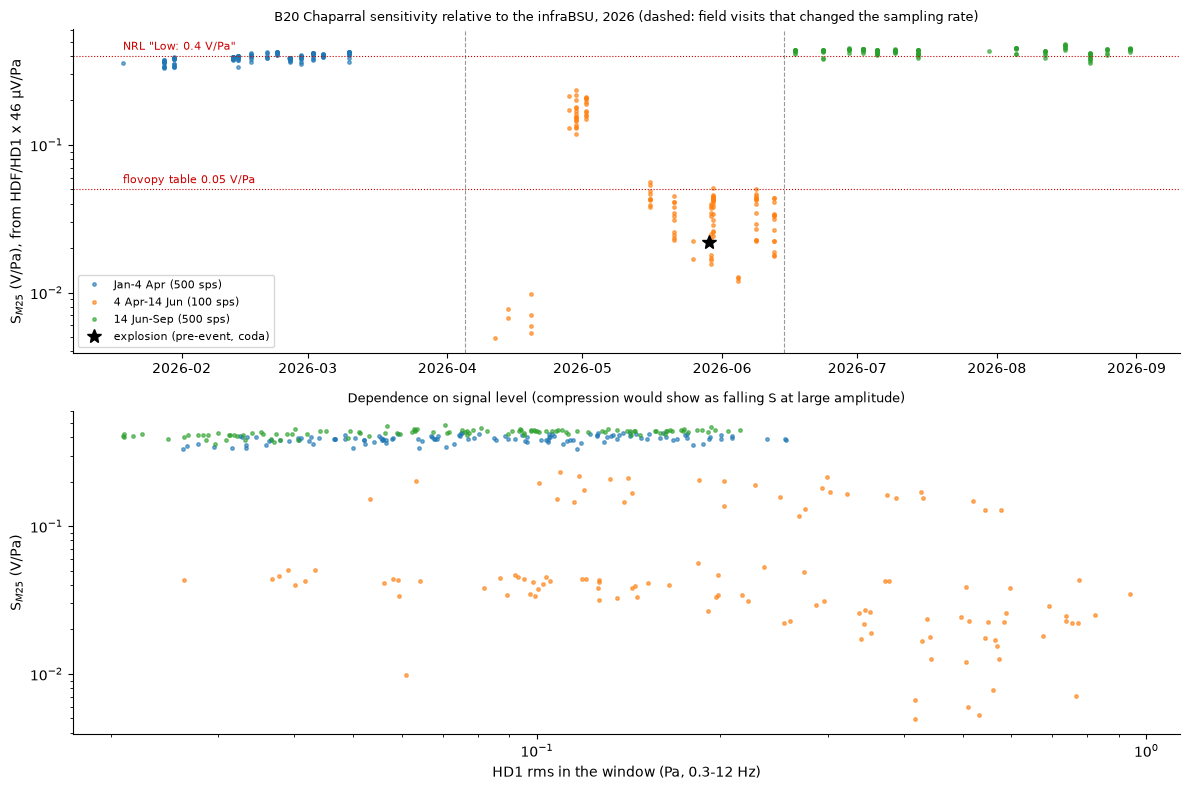

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(12, 8))
ax = axs[0]
for e, g in win.groupby('epoch', observed=True):
    ax.semilogy(g.t, g.S_V_per_Pa, '.', ms=5, alpha=0.6, label=e)
ex = win[win.source.str.startswith('explosion')]
ax.semilogy(ex.t, ex.S_V_per_Pa, 'k*', ms=10, label='explosion (pre-event, coda)')
for v in VISITS:
    ax.axvline(pd.Timestamp(v.datetime), color='#999999', ls='--', lw=0.8)
for val, lab in ((0.4, 'NRL "Low: 0.4 V/Pa"'), (0.05, 'flovopy table 0.05 V/Pa')):
    ax.axhline(val, color='#cc0000', ls=':', lw=0.8)
    ax.text(win.t.min(), val * 1.1, lab, fontsize=8, color='#cc0000')
ax.set(ylabel='S$_{M25}$ (V/Pa), from HDF/HD1 x 46 µV/Pa', title='B20 Chaparral sensitivity relative to the infraBSU, 2026 '
       '(dashed: field visits that changed the sampling rate)')
ax.legend(fontsize=8)
ax = axs[1]
for e, g in win.groupby('epoch', observed=True):
    ax.loglog(g.dd1_rms_Pa, g.S_V_per_Pa, '.', ms=5, alpha=0.6, label=e)
ax.set(xlabel='HD1 rms in the window (Pa, 0.3-12 Hz)', ylabel='S$_{M25}$ (V/Pa)',
       title='Dependence on signal level (compression would show as falling S at large amplitude)')
for a in axs:
    a.title.set_fontsize(9)
fig.tight_layout()
fig.savefig(OUT / 'chaparral_sensitivity.png', dpi=150, bbox_inches='tight')

## Result

* **In normal operation the M25 is close to its nominal sensitivity.** From 354 coherent, unclipped windows
  after 42 launches and the explosion:
  * January to 4 April (500 samples/s): 0.36–0.42 V/Pa (median 0.39, 13 launches);
  * 14 June to September (500 samples/s): 0.39–0.46 V/Pa (median 0.44, 14 launches).

  That matches the NRL "Low: 0.4 V/Pa" entry, so **0.4 V/Pa is the correct value** (relative to a 46 µV/Pa
  infraBSU). The small rise through the year (about 12%) is within the infraBSU's own calibration
  uncertainty, or could be temperature.
* **Between the field visits of 4 April and 14 June (100 samples/s) the M25 was not working properly.** Its
  apparent sensitivity jumped between levels:
  * 0.005–0.007 V/Pa on 11–19 April;
  * 0.15–0.19 V/Pa on 28 April – 1 May;
  * 0.02–0.04 V/Pa from 15 May to 12 June. **At the explosion** it was 0.022 V/Pa in the coda and 0.042 V/Pa
    after the Atlas V launch that evening.

  Within single events it also rises as the signal decays (compression at higher levels). That pattern
  points to a fault or a mis-set gain during that visit interval, not to a calibration error.
* **Consequences.** `newglenn.yaml` keeps 0.4 V/Pa, the sensor's true sensitivity. HDF is not used for the
  explosion: it clipped at 1 Vpp, and at the time it read about 10–20 times low and unstably. The HDF/HD1
  ratio of about 0.05 in notebooks 22 and 30 is the same anomaly seen at the configured 0.4 V/Pa
  (0.4 × 0.05 ≈ 0.02 V/Pa).
* **Field check.** It is worth finding out what changed at B20 on 4 April and 14 June besides the sampling
  rate (M25 gain switch, cabling, a swapped unit).
* **Artemis II.** B20's Centaur has no data for days 071–093, so the launch cannot be used here.